# Actividad :  Resolución de problema mediante búsqueda heurística





Actualización:

*   2026/02/16, Fichero creado






## Importante

El código siguiente es el que debe usarse para la ejecución de la actividad.
En caso de requerir modificaciones se subirán ficheros de sustitución al aula de la asignatura


In [2]:
%pip install -q simpleai flask pydot graphviz

Note: you may need to restart the kernel to use updated packages.


In [3]:
import shutil, sys
print(sys.executable)
print(shutil.which('dot'))

c:\Users\alexi\AppData\Local\Programs\Python\Python313\python.exe
C:\Program Files\Graphviz\bin\dot.EXE


In [4]:
#!/usr/bin/env python
# coding: utf-8

# 2024 Modified by: Alejandro Cervantes
# Remember installing pyplot and flask if you want to use WebViewer

# NOTA: WebViewer sólo funcionará si ejecutáis en modo local

from __future__ import print_function

import math
import shutil
import socket
from IPython.display import Image, display
from simpleai.search.viewers import BaseViewer,ConsoleViewer,WebViewer
from simpleai.search import SearchProblem, astar, breadth_first, depth_first, uniform_cost



class GameWalkPuzzle(SearchProblem):

    def __init__(self, board, costs, heuristic_number):
        self.board = board
        self.goal = (0, 0)
        self.costs = costs
        self.heuristic_number = heuristic_number
        for y in range(len(self.board)):
            for x in range(len(self.board[y])):
                if self.board[y][x].lower() == "t":
                    self.initial = (x, y)
                elif self.board[y][x].lower() == "p":
                    self.goal = (x, y)

        super(GameWalkPuzzle, self).__init__(initial_state=self.initial)

    def actions(self, state):
        actions = []
        for action in list(self.costs.keys()):
            newx, newy = self.result(state, action)
            if self.board[newy][newx] != "#":
                actions.append(action)
        # print(actions)
        return actions

    def result(self, state, action):
        x, y = state

        if action.count("up"):
            y -= 1
        if action.count("down"):
            y += 1
        if action.count("left"):
            x -= 1
        if action.count("right"):
            x += 1

        new_state = (x, y)
        # print(new_state)
        return new_state

    def is_goal(self, state):
        return state == self.goal

    def cost(self, state, action, state2):
        return self.costs[action]

    # Esta función heurística es la distancia entre el estado actual
    # el objetivo (único) identificado como self.goal
    def heuristic1(self, state):
        x, y = state
        gx, gy = self.goal
        return abs(x - gx) + abs(y - gy)

    def heuristic2(self, state):
        x, y = state
        gx, gy = self.goal
        return max(abs(x - gx),abs(y - gy))

    def heuristic3(self, state):
        x, y = state
        gx, gy = self.goal
        return 2*(abs(x - gx) + abs(y - gy))

    def heuristic(self,state):
      if self.heuristic_number == 1:
          return self.heuristic1(state)
      elif self.heuristic_number == 2:
          return self.heuristic2(state)
      elif self.heuristic_number == 3:
          return self.heuristic3(state)
      else:
        raise Exception("El número de la función heurística debe estar entre 1 y 3. Revise la inicialización del problema.")

def searchInfo (problem,result,use_viewer):
    def getTotalCost (problem,result):
        originState = problem.initial_state
        totalCost = 0
        for action,endingState in result.path():
            if action is not None:
                totalCost += problem.cost(originState,action,endingState)
                originState = endingState
        return totalCost


    res = "Total length of solution: {0}\n".format(len(result.path()))
    res += "Total cost of solution: {0}\n".format(getTotalCost(problem,result))

    if use_viewer:
        stats = [{'name': stat.replace('_', ' '), 'value': value}
                         for stat, value in list(use_viewer.stats.items())]

        exp = [ {'name' : 'expanded nodes', 'value' : s['value']-1 } for s in stats if s['name'] == 'visited nodes' ]
        stats = stats + exp

        for s in stats:
            res+= '{0}: {1}\n'.format(s['name'],s['value'])
    return res


def resultado_experimento(problem,MAP,result,used_viewer):
    path = [x[1] for x in result.path()]

    for y in range(len(MAP)):
        for x in range(len(MAP[y])):
            if (x, y) == problem.initial:
                print("T", end='')
            elif (x, y) == problem.goal:
                print("P", end='')
            elif (x, y) in path:
                print("·", end='')
            else:
                print(MAP[y][x], end='')
        print()

    info=searchInfo(problem,result,used_viewer)
    print(info)

# Muestra la traza de la búsqueda (ConsoleViewer no interactivo) y guarda los
# nodos elegidos para dibujar al final el árbol completo de nodos expandidos.
# El grafo de ConsoleViewer/WebViewer sólo muestra la frontera y, al terminar,
# el camino solución. Requiere el ejecutable "dot" de Graphviz
class ExpandedTreeViewer(ConsoleViewer):

    def __init__(self, interactive=False):
        super(ExpandedTreeViewer, self).__init__(interactive=interactive)
        self.chosen_nodes = []
        self.solution_node = None

    def handle_chosen_node(self, node, is_goal=None):
        super(ExpandedTreeViewer, self).handle_chosen_node(node, is_goal)
        self.chosen_nodes.append(node)

    def build_expanded_tree(self, title):
        from pydot import Dot, Edge, Node

        solution_path = set()
        node = self.solution_node
        while node is not None:
            solution_path.add(id(node))
            node = node.parent

        graph = Dot(graph_type='digraph', label=title, labelloc='t')
        # Se usa id(node) porque dos nodos distintos pueden tener el mismo estado
        for order, node in enumerate(self.chosen_nodes, 1):
            color = self.solution_color if id(node) in solution_path else self.fringe_color
            graph.add_node(Node(str(id(node)),
                                label='{0}\n{1}'.format(order, node.state_representation()),
                                style='filled',
                                shape='circle',
                                fillcolor=color,
                                fontsize=self.font_size))
            if node.parent is not None:
                graph.add_edge(Edge(str(id(node.parent)),
                                    str(id(node)),
                                    label=node.action_representation(),
                                    fontsize=self.font_size))
        return graph

    def show_expanded_tree(self, title):
        if shutil.which('dot') is None:
            print("No se puede dibujar el árbol: falta el ejecutable 'dot' de Graphviz en el PATH")
            return
        display(Image(self.build_expanded_tree(title).create_png()))


# Se elige un puerto libre en cada viewer: el servidor de WebViewer sigue vivo
# hasta reiniciar el kernel y no se puede reutilizar el puerto
def local_web_viewer():
    if shutil.which('dot') is None:
        raise RuntimeError("WebViewer necesita el ejecutable 'dot' de Graphviz en el PATH")
    with socket.socket() as s:
        s.bind(('127.0.0.1', 0))
        port = s.getsockname()[1]
    return WebViewer(host='127.0.0.1', port=port)


def main(MAP_ASCII,COSTS,algorithms,heuristic_number=1,viewer_factory=BaseViewer):
    MAP = [list(x) for x in MAP_ASCII.split("\n") if x]
    print("MAP after process -> ", MAP)
    for algorithm in algorithms:
      problem = GameWalkPuzzle(MAP,COSTS,heuristic_number)
      used_viewer=viewer_factory()
      # Probad también ConsoleViewer para depurar
      # No podréis usar WebViewer en Collab para ver los árboles

      # Mostramos tres experimentos
      print ("Experimento con algoritmo {}:".format(algorithm))

      result = algorithm(problem, graph_search=True,viewer=used_viewer)
      resultado_experimento(problem,MAP,result,used_viewer)
      if isinstance(used_viewer,ExpandedTreeViewer):
          used_viewer.show_expanded_tree("Nodos expandidos: {} (el número indica el orden)".format(algorithm.__name__))





Aquí se define el mapa base para todos los casos.

In [5]:
# Mapa para todos los casos

MAP_ASCII_ORIG = """
#########
# T     #
# # ### #
#   #P  #
# ##    #
#       #
#       #
#########
"""


MAP after process ->  [['#', '#', '#', '#', '#', '#', '#', '#', '#'], ['#', ' ', 'T', ' ', ' ', ' ', ' ', ' ', '#'], ['#', ' ', '#', ' ', '#', '#', '#', ' ', '#'], ['#', ' ', ' ', ' ', '#', 'P', ' ', ' ', '#'], ['#', ' ', '#', '#', ' ', ' ', ' ', ' ', '#'], ['#', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '#'], ['#', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '#'], ['#', '#', '#', '#', '#', '#', '#', '#', '#']]
Experimento con algoritmo <function breadth_first at 0x0000023EDBA19A80>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in 

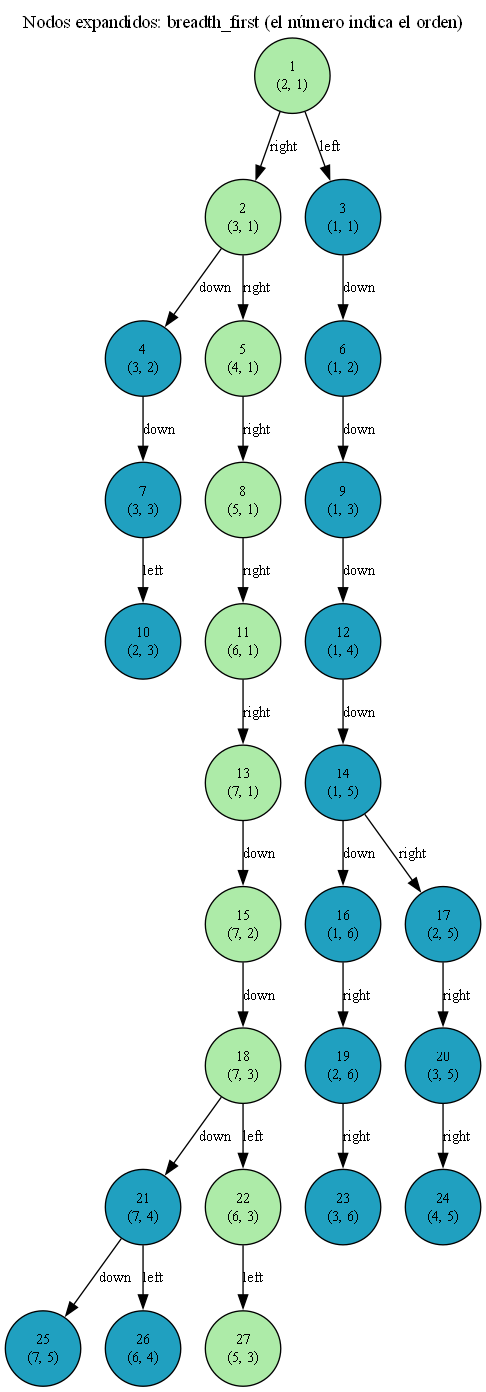

Experimento con algoritmo <function depth_first at 0x0000023EDBA19C60>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(1, 1)>, Node <(3, 1)>]
EVENT: chosen_node
Chosen node: Node <(1, 1)>
Not goal
EVENT: expanded
Expanded [Node <(1, 1)>]
Successors: [[Node <(1, 2)>, Node <(2, 

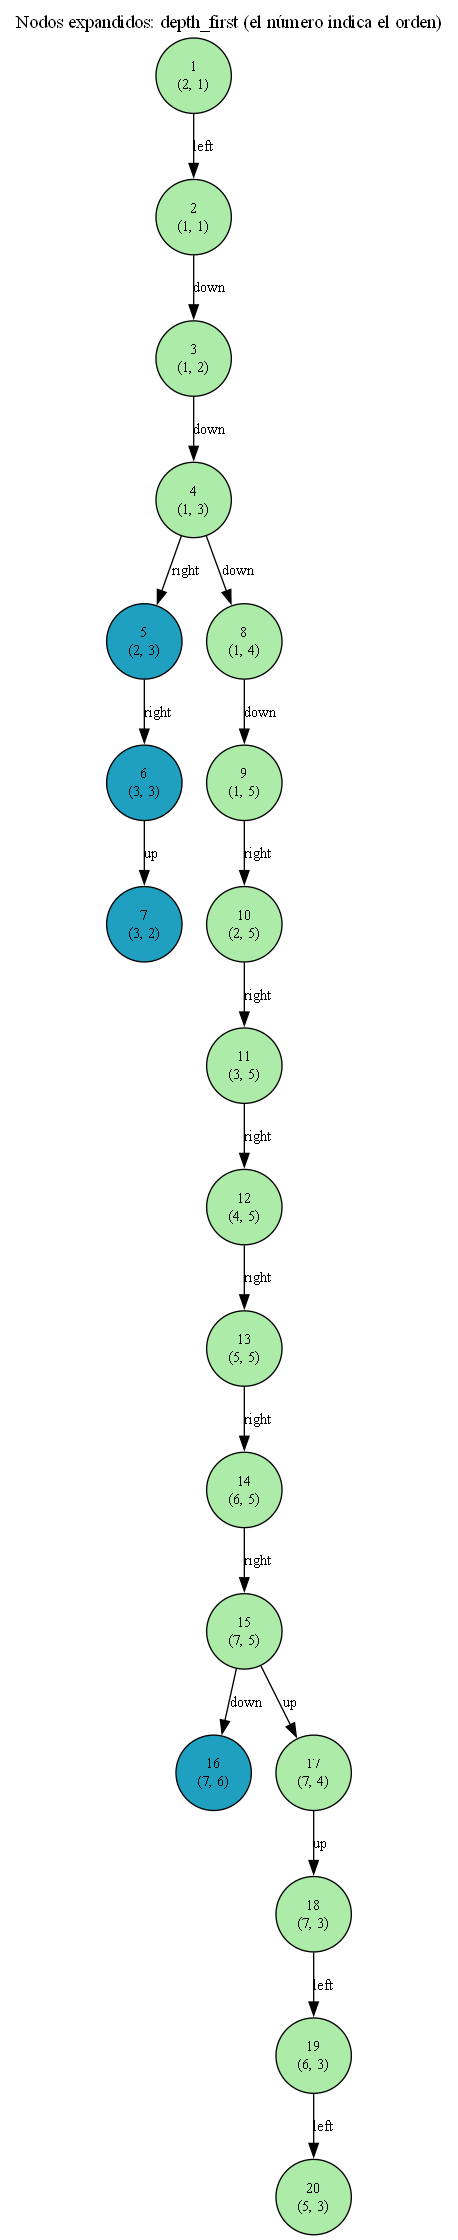

: 

In [ ]:

# Configuración y llamada para el caso 1
# Se ejecutan los algoritmos de búsqueda en amplitud y búsqueda en profundidad

MAP_ASCII=MAP_ASCII_ORIG
COSTS = {
    "up": 1.0,
    "down": 1.0,
    "right": 1.0,
    "left": 1.0,
}

algorithms=(breadth_first,depth_first)
COSTS_CASO_1=COSTS
algorithms_caso_1=algorithms
main (MAP_ASCII,COSTS,algorithms,viewer_factory=ExpandedTreeViewer)

Visualización paso a paso del caso 1 con WebViewer (sólo en local). Requiere Graphviz.

*   Poned `USE_WEB_VIEWER = True` para ejecutarla. Está desactivada para que "Ejecutar todo" no se quede bloqueado.
*   La celda no termina hasta que el algoritmo acaba: abrid el enlace que aparece en la salida y usad los controles de la página. Se abre un enlace nuevo por cada algoritmo.
*   No uséis "Stop running": cierra el proceso y mata el kernel del cuaderno.


In [ ]:
# Caso 1 con WebViewer

USE_WEB_VIEWER = False

if USE_WEB_VIEWER:
    main (MAP_ASCII_ORIG,COSTS_CASO_1,algorithms_caso_1,viewer_factory=local_web_viewer)

MAP after process ->  [['#', '#', '#', '#', '#', '#', '#', '#', '#'], ['#', ' ', 'T', ' ', ' ', ' ', ' ', ' ', '#'], ['#', ' ', '#', ' ', '#', '#', '#', ' ', '#'], ['#', ' ', ' ', ' ', '#', 'P', ' ', ' ', '#'], ['#', ' ', '#', '#', ' ', ' ', ' ', ' ', '#'], ['#', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '#'], ['#', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '#'], ['#', '#', '#', '#', '#', '#', '#', '#', '#']]
Experimento con algoritmo <function breadth_first at 0x0000023EDBA19A80>:
Starting the WebViewer, access it from your web browser, navigating to the address:
http://localhost:58299
To stop the WebViewer, use the "Stop running" link (on the viewer site, from the browser)
 * Serving Flask app 'simpleai.search.web_viewer_server'
 * Debug mode: off


 * Running on http://127.0.0.1:58299
Press CTRL+C to quit
127.0.0.1 - - [31/Oct/2026 08:10:22] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:22] "GET /static/styles.css HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:22] "GET /static/jquery.panzoom.min.js HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:22] "GET /static/EventSource.js HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:22] "GET /static/main.js HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:22] "GET /graph HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:23] "GET /static/jquery-2.0.2.min.js HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:23] "GET /static/angular.min.js HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:23] "GET /event_stream HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:23] "GET /graph?unique=1793459423904 HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08:10:23] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [31/Oct/2026 08:10:38] "GET /control/play HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 08

In [ ]:
# Configuración y llamada para el caso 2
# Se utiliza el mismo mapa pero se varían los costes

MAP_ASCII=MAP_ASCII_ORIG
COSTS = {
    "up": 1.0,
    "down": 1.0,
    "right": 1.0,
    "left": 4.0,
}



algorithms=(breadth_first,uniform_cost,astar)
main (MAP_ASCII,COSTS,algorithms)

MAP after process ->  [['#', '#', '#', '#', '#', '#', '#', '#', '#'], ['#', ' ', 'T', ' ', ' ', ' ', ' ', ' ', '#'], ['#', ' ', '#', ' ', '#', '#', '#', ' ', '#'], ['#', ' ', ' ', ' ', '#', 'P', ' ', ' ', '#'], ['#', ' ', '#', '#', ' ', ' ', ' ', ' ', '#'], ['#', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '#'], ['#', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '#'], ['#', '#', '#', '#', '#', '#', '#', '#', '#']]
Experimento con algoritmo <function breadth_first at 0x000001818EC0DC60>:
#########
# T·····#
# # ###·#
#   #P··#
# ##    #
#       #
#       #
#########
Total length of solution: 10
Total cost of solution: 15.0
max fringe size: 7
visited nodes: 27
iterations: 27
expanded nodes: 26

Experimento con algoritmo <function uniform_cost at 0x000001818EC0EC00>:
#########
#·T     #
#·# ### #
#·  #P  #
#·##··  #
#····   #
#       #
#########
Total length of solution: 12
Total cost of solution: 14.0
max fringe size: 8
visited nodes: 34
iterations: 34
expanded nodes: 33

Experimento con algoritmo <functio

In [ ]:

# Configuración y llamada para el caso 3
# Se utiliza el mismo mapa y se usan diferentes heurísticas

MAP_ASCII=MAP_ASCII_ORIG
COSTS = {
    "up": 1.0,
    "down": 1.0,
    "right": 1.0,
    "left": 4.0,
}

algorithms=(astar,)
print ("Heurística 1\n")
main (MAP_ASCII,COSTS,algorithms,1)
print ("Heurística 2\n")
main (MAP_ASCII,COSTS,algorithms,2)
print ("Heurística 3\n")
main (MAP_ASCII,COSTS,algorithms,3)



Heurística 1

MAP after process ->  [['#', '#', '#', '#', '#', '#', '#', '#', '#'], ['#', ' ', 'T', ' ', ' ', ' ', ' ', ' ', '#'], ['#', ' ', '#', ' ', '#', '#', '#', ' ', '#'], ['#', ' ', ' ', ' ', '#', 'P', ' ', ' ', '#'], ['#', ' ', '#', '#', ' ', ' ', ' ', ' ', '#'], ['#', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '#'], ['#', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '#'], ['#', '#', '#', '#', '#', '#', '#', '#', '#']]
Experimento con algoritmo <function astar at 0x000001818EC0ED40>:
#########
#·T     #
#·# ### #
#·  #P  #
#·##··  #
#····   #
#       #
#########
Total length of solution: 12
Total cost of solution: 14.0
max fringe size: 10
visited nodes: 27
iterations: 27
expanded nodes: 26

Heurística 2

MAP after process ->  [['#', '#', '#', '#', '#', '#', '#', '#', '#'], ['#', ' ', 'T', ' ', ' ', ' ', ' ', ' ', '#'], ['#', ' ', '#', ' ', '#', '#', '#', ' ', '#'], ['#', ' ', ' ', ' ', '#', 'P', ' ', ' ', '#'], ['#', ' ', '#', '#', ' ', ' ', ' ', ' ', '#'], ['#', ' ', ' ', ' ', ' ', ' ', ' ', ' 